# TripGenie — Personalized Hybrid Recommendations

## 1. Goal and scope
Combine existing TF-IDF content similarity, supplied popularity, and explicit user preferences for interests, daily budget, season, and trip duration. The result is an explainable metadata/content hybrid: **no collaborative filtering**, user interactions, or learned preference weights are used.

Return up to five distinct destinations with component scores, effective weights, and weighted contributions. Preserve source variants during scoring; retain only the highest-scoring variant per normalized destination name in results. Exclude every variant of a selected destination. Similarity and hybrid scores are ranking utilities, not probabilities or independently verified travel suitability.

## 2. Load data and reuse the fitted content recommender
The notebook imports `backend/recommender/hybrid_recommender.py`, which accepts the existing `ContentBasedRecommender`. Fit TF-IDF once and reuse it; hybrid requests do not refit. Dependencies are the same as notebook 03: pandas, NumPy, scikit-learn, Matplotlib, Seaborn, and ipykernel. Dataset files are read only.

In [1]:
from pathlib import Path
import sys
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/processed/india_tourism_processed.json").is_file()), None)
if root is None:
    raise FileNotFoundError("Run from within the TripGenie repository after preprocessing.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from backend.recommender.content_recommender import ContentBasedRecommender, destination_key
from backend.recommender.hybrid_recommender import HybridRecommender, DEFAULT_WEIGHTS, season_matches

processed_path = root / "data/processed/india_tourism_processed.json"
source_path = root / "data/india_tourism_dataset.json"
hashes = {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in [processed_path, source_path]}
content = ContentBasedRecommender.from_json(processed_path)
hybrid = HybridRecommender(content)
catalogue = content.catalogue
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
components = list(DEFAULT_WEIGHTS)

def observe(text):
    display(Markdown("**Observations.** " + text))

def show_results(results):
    columns = ["id", "destination_name", "state", "hybrid_score"] + [f"{k}_score" for k in components]
    display(results[columns].style.format({c: "{:.3f}" for c in columns if c.endswith("score")}))

display(catalogue[["id", "destination_name", "popularity_score", "trip_types_clean", "best_seasons_clean", "ideal_days"]].head())
observe(f"Loaded {len(catalogue)} catalogue entries and reused a TF-IDF matrix with {content.tfidf_matrix.shape[1]:,} features. "
        "No source variants are merged during scoring.")

,id,destination_name,popularity_score,trip_types_clean,best_seasons_clean,ideal_days
0,1,Goa,9,"[beach, culture, food, nightlife, wellness, ph...","[winter, post monsoon]",5.0
1,2,Ladakh (Leh),9,"[adventure, nature, culture, religious, photog...","[summer, early autumn]",7.0
2,3,Jaipur,9,"[heritage, culture, photography, shopping, food]","[winter, late autumn]",3.0
3,4,Varanasi (Kashi),9,"[religious, spiritual, culture, photography]","[winter, early spring]",3.0
4,5,Agra,10,"[heritage, photography, short break]","[winter, late autumn]",2.0


**Observations.** Loaded 100 catalogue entries and reused a TF-IDF matrix with 8,326 features. No source variants are merged during scoring.

## 3. Explainable scoring policy
All component scores lie in [0, 1]. The final score is the sum of each component multiplied by its **effective weight**.

| Component | Rule | Interpretation |
|---|---|---|
| Content | Destination cosine, interest-text cosine, or their equal average when both are supplied | Reuses the existing fitted TF-IDF vocabulary. |
| Popularity | Catalogue min–max normalization; unknown values score 0; a constant known score gets 1 | A supplied metadata prior; the rating methodology is undocumented. |
| Interests | Fraction of distinct requested normalized interest phrases present in `trip_types_clean` | Exact tag coverage complements semantic content matching. Four reviewed aliases from preprocessing are reused. |
| Budget | `min(1, daily_budget / tier_daily_upper_endpoint)`; unknown/invalid ranges score 0 | A conservative upper-end affordability ratio; it is not proof of exact trip cost. |
| Season | 1 if the requested season appears in best-season labels and no avoid-season label matches; otherwise 0 | Avoid-season matches take precedence. Conditional prose makes this a heuristic. |
| Duration | `min(requested_days, ideal_days) / max(requested_days, ideal_days)`; unknown/invalid ideals score 0 | A soft proximity score centered on ideal duration. |

Default weights are content 0.30, popularity 0.10, interests 0.20, budget 0.15, season 0.15, and duration 0.10. A supplied weight dictionary overrides named defaults. Weights must be finite and nonnegative. Components without user input are deactivated, and the remaining weights are normalized to sum to one; zero total active weight is rejected. No preferences and no reference destination gives a popularity-only ranking.

Interests are a list of phrases, not a raw sentence. Fully unknown interests give zero content/interest matches but other active components may still rank destinations; the breakdown makes this visible. Supported seasons are winter, summer, spring, autumn (`fall` is an alias), monsoon, and post-monsoon. Word boundaries prevent substring matches; pre/post-monsoon phrases are not treated as monsoon. Month strings are not converted to seasons.

**Costs:** use the source's undocumented daily currency units and choose `budget`, `mid-range`, or `luxury`. No per-person assumption is applied. Soft preferences do not exclude poor matches. Optional `strict_filters=True` requires the budget to cover the lower daily endpoint, days to fall within minimum/maximum, and a best-season match without an avoid-season match. It may return fewer than five destinations, including none. It does not enforce interests, verified transport access, permits, or safety.

,Default weight
content,0.30
popularity,0.10
interests,0.20
budget,0.15
season,0.15
duration,0.10


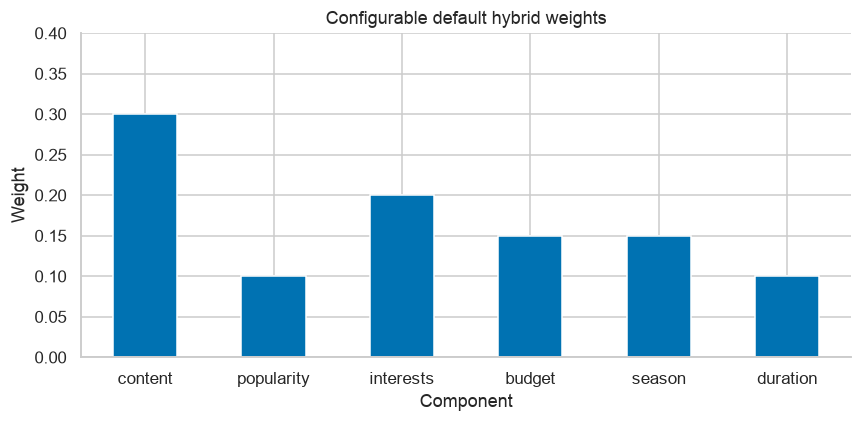

In [2]:
display(pd.Series(DEFAULT_WEIGHTS, name="Default weight").to_frame())
fig, ax = plt.subplots(figsize=(8, 4))
pd.Series(DEFAULT_WEIGHTS).plot.bar(ax=ax, color="#0072b2", rot=0)
ax.set(title="Configurable default hybrid weights", xlabel="Component", ylabel="Weight", ylim=(0, 0.4))
fig.tight_layout(); plt.show()

## 4. Top five personalized destinations with score breakdowns
Demonstrate a traveler who likes Goa, beaches and water sports, has a daily budget of 3,000 source units in the budget tier, travels in winter, and has three days. These are example preferences, not a real user's profile. Scores and observations are computed from the actual catalogue.

The displayed breakdown separates raw component scores from weighted contributions. All facts shown for a destination come from one selected source variant; conflicting entries are not combined.

Example profile: {'selected_destination': 1, 'interests': ['beach', 'water sports'], 'daily_budget': 3000, 'budget_tier': 'budget', 'season': 'winter', 'trip_days': 3}


,id,destination_name,state,hybrid_score,content_score,popularity_score,interests_score,budget_score,season_score,duration_score
0,30,Varkala,Kerala,0.568,0.060,0.500,0.500,1.000,1.000,1.000
1,26,Pondicherry (Puducherry),Puducherry,0.560,0.032,0.500,0.500,1.000,1.000,1.000
2,31,Havelock Island (Swaraj Dweep),Andaman and Nicobar Islands,0.545,0.099,0.833,0.500,0.545,1.000,1.000
3,39,Varanasi (Kashi),Uttar Pradesh,0.505,0.018,1.000,0.000,1.000,1.000,1.000
4,32,Neil Island (Shaheed Dweep),Andaman and Nicobar Islands,0.496,0.036,0.500,0.500,0.789,1.000,0.667


,Effective weight
content_weight,0.3
popularity_weight,0.1
interests_weight,0.2
budget_weight,0.15
season_weight,0.15
duration_weight,0.1


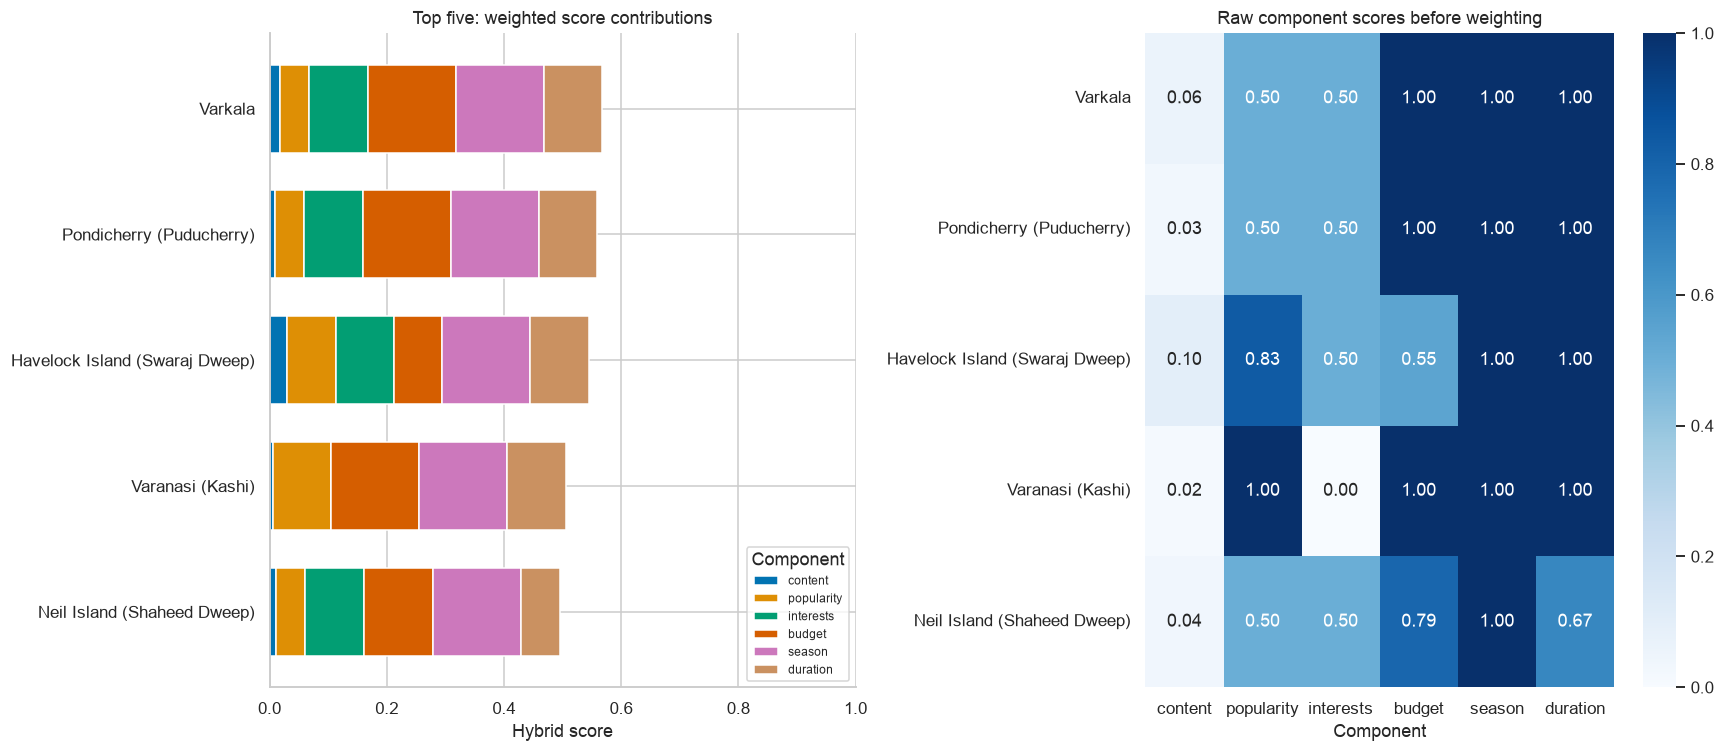

**Observations.** Returned 5 unique destinations. The highest-scoring entry is Varkala at 0.568. Review individual components: a high overall score can still include a weak budget, interest, or season match.

In [3]:
profile = {"selected_destination": 1, "interests": ["beach", "water sports"],
           "daily_budget": 3000, "budget_tier": "budget", "season": "winter", "trip_days": 3}
results = hybrid.recommend(**profile)
print("Example profile:", profile)
show_results(results)
if not results.empty:
    effective_weights = results.iloc[0][[f"{k}_weight" for k in components]]
    display(effective_weights.rename("Effective weight").to_frame())
    contributions = results.set_index("destination_name")[[f"{k}_contribution" for k in components]]
    contributions.columns = components
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    contributions.iloc[::-1].plot.barh(stacked=True, ax=axes[0], width=0.7)
    axes[0].set(title="Top five: weighted score contributions", xlabel="Hybrid score", ylabel="", xlim=(0, 1))
    axes[0].legend(title="Component", fontsize=8, loc="lower right")
    score_matrix = results.set_index("destination_name")[[f"{k}_score" for k in components]]
    score_matrix.columns = components
    sns.heatmap(score_matrix, vmin=0, vmax=1, annot=True, fmt=".2f", cmap="Blues", ax=axes[1])
    axes[1].set(title="Raw component scores before weighting", xlabel="Component", ylabel="")
    fig.tight_layout(); plt.show()
observe(f"Returned {len(results)} unique destinations. " +
        (f"The highest-scoring entry is {results.iloc[0].destination_name} at {results.iloc[0].hybrid_score:.3f}. " if len(results) else "") +
        "Review individual components: a high overall score can still include a weak budget, interest, or season match.")

## 5. Strict preferences and configurable-weight sensitivity
Compare soft ranking with strict structured filters. Strict budget filtering uses the **lower** cost endpoint, so passing it does not guarantee every quoted daily expense fits the budget. Seasonal matches are still catalogue-text heuristics.

Change popularity weight while retaining other configured weights. Active weights are renormalized after each change. This illustrates rank sensitivity, not an optimized configuration; increasing one weight reduces the relative contribution of the others.

Strict-filter results


,id,destination_name,state,hybrid_score,content_score,popularity_score,interests_score,budget_score,season_score,duration_score
0,30,Varkala,Kerala,0.568,0.060,0.500,0.500,1.000,1.000,1.000
1,26,Pondicherry (Puducherry),Puducherry,0.560,0.032,0.500,0.500,1.000,1.000,1.000
2,31,Havelock Island (Swaraj Dweep),Andaman and Nicobar Islands,0.545,0.099,0.833,0.500,0.545,1.000,1.000
3,39,Varanasi (Kashi),Uttar Pradesh,0.505,0.018,1.000,0.000,1.000,1.000,1.000
4,32,Neil Island (Shaheed Dweep),Andaman and Nicobar Islands,0.496,0.036,0.500,0.500,0.789,1.000,0.667


,configured_popularity_weight,effective_popularity_weight,top_destination,shared_with_default_top5
0,0.0,0.00,Varkala,4
1,0.1,0.10,Varkala,5
2,0.3,0.25,Havelock Island (Swaraj Dweep),4
3,0.6,0.40,Varanasi (Kashi),2


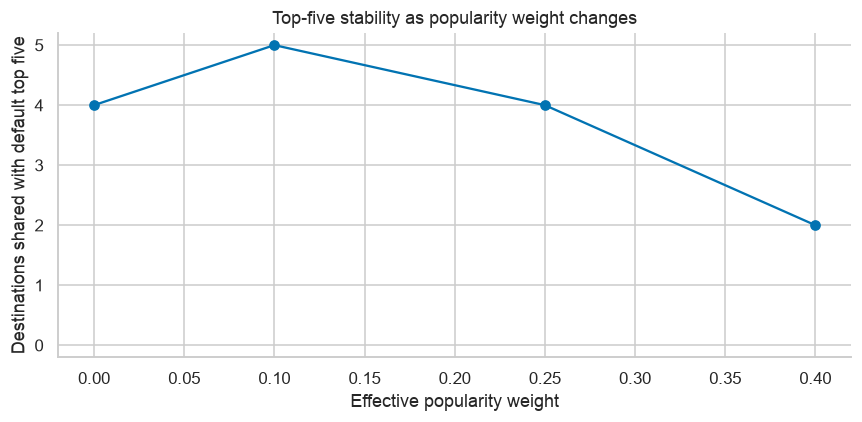

**Observations.** Strict filters returned 5 destinations for the example profile. The sensitivity table shows how candidate identity and rank respond to configurable weights.

In [4]:
strict_results = hybrid.recommend(**profile, strict_filters=True)
print("Strict-filter results")
show_results(strict_results)
sensitivity_rows = []
for popularity_weight in [0.0, 0.1, 0.3, 0.6]:
    ranked = hybrid.recommend(**profile, weights={"popularity": popularity_weight})
    base_names = set(results.destination_name.map(destination_key))
    new_names = set(ranked.destination_name.map(destination_key))
    sensitivity_rows.append({"configured_popularity_weight": popularity_weight,
        "effective_popularity_weight": ranked.iloc[0].popularity_weight if len(ranked) else np.nan,
        "top_destination": ranked.iloc[0].destination_name if len(ranked) else None,
        "shared_with_default_top5": len(base_names & new_names)})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sensitivity.effective_popularity_weight, sensitivity.shared_with_default_top5, marker="o")
ax.set(title="Top-five stability as popularity weight changes", xlabel="Effective popularity weight", ylabel="Destinations shared with default top five", ylim=(-0.2, 5.2))
ax.set_yticks(range(6)); fig.tight_layout(); plt.show()
observe(f"Strict filters returned {len(strict_results)} destinations for the example profile. "
        "The sensitivity table shows how candidate identity and rank respond to configurable weights.")

## 6. Basic evaluation and comparison with content-only ranking
Use four explicit synthetic profiles covering beach, adventure, heritage, and wildlife interests. Compare hybrid and content-only results using requested-tag coverage, fraction whose daily **upper endpoint** fits budget, season-match fraction, and fraction whose recommended duration range contains the requested days.

These features participate in hybrid scoring, so these metrics measure preference agreement, not independent precision, recall, accuracy, or satisfaction. Content-only ranking is a reference baseline and does not enforce budget/season/duration preferences. No user interaction data exists, and no collaborative component is evaluated. Do not select weights solely from these four examples.

,profile,method,returned_count,interest_coverage,budget_upper_fit,season_fit,duration_range_fit
0,Beach,Hybrid,5,0.4,0.6,1.0,1.0
1,Beach,Content-only,5,0.6,0.2,0.2,0.8
2,Adventure,Hybrid,5,0.6,1.0,1.0,0.4
3,Adventure,Content-only,5,0.7,1.0,0.8,0.6
4,Heritage,Hybrid,5,0.5,0.0,1.0,1.0
5,Heritage,Content-only,5,0.4,0.0,0.6,1.0
6,Wildlife,Hybrid,5,0.5,0.4,1.0,1.0
7,Wildlife,Content-only,5,0.6,0.2,0.4,1.0


,interest_coverage,budget_upper_fit,season_fit,duration_range_fit
method,,,,
Content-only,0.575,0.35,0.5,0.85
Hybrid,0.500,0.50,1.0,0.85


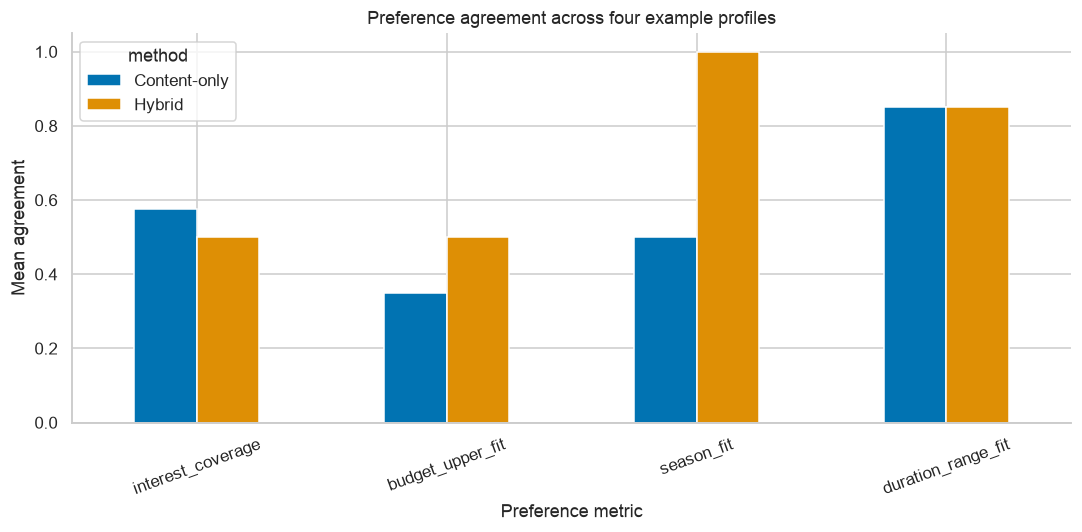

**Observations.** For these profiles, mean interest coverage is Content-only: 0.575; Hybrid: 0.500. Other agreement metrics are shown above. These synthetic-profile checks do not establish real user preference accuracy.

In [5]:
profiles = {
    "Beach": profile,
    "Adventure": {"selected_destination": 2, "interests": ["adventure", "trekking"], "daily_budget": 5000, "season": "summer", "trip_days": 7},
    "Heritage": {"selected_destination": 3, "interests": ["heritage", "culture"], "daily_budget": 2500, "season": "winter", "trip_days": 3},
    "Wildlife": {"interests": ["wildlife", "birding"], "daily_budget": 3500, "season": "winter", "trip_days": 3}
}

def preference_metrics(rows, preferences):
    if rows.empty:
        return {"returned_count": 0, "interest_coverage": np.nan, "budget_upper_fit": np.nan,
                "season_fit": np.nan, "duration_range_fit": np.nan}
    requested = set(preferences["interests"])
    tier = "budget_category"
    return {"returned_count": len(rows),
        "interest_coverage": np.mean([len(set(tags) & requested) / len(requested) for tags in rows.trip_types_clean]),
        "budget_upper_fit": rows[f"{tier}.total_daily_high"].le(preferences["daily_budget"]).mean(),
        "season_fit": np.mean([season_matches(best, preferences["season"]) and not season_matches(avoid, preferences["season"])
                               for best, avoid in zip(rows.best_seasons_clean, rows.avoid_seasons_clean)]),
        "duration_range_fit": (rows.minimum_days.le(preferences["trip_days"]) & rows.maximum_days.ge(preferences["trip_days"])).mean()}

evaluation_rows = []
for name, preferences in profiles.items():
    hybrid_rows = hybrid.recommend(**preferences)
    content_rows = content.recommend(selected_destination=preferences.get("selected_destination"), interests=preferences["interests"])
    for method, ranked in [("Hybrid", hybrid_rows), ("Content-only", content_rows)]:
        details = catalogue.set_index("id").loc[ranked.id].reset_index()
        evaluation_rows.append({"profile": name, "method": method, **preference_metrics(details, preferences)})
evaluation = pd.DataFrame(evaluation_rows)
display(evaluation.round(3))
metric_columns = ["interest_coverage", "budget_upper_fit", "season_fit", "duration_range_fit"]
means = evaluation.groupby("method")[metric_columns].mean()
display(means.round(3))
fig, ax = plt.subplots(figsize=(10, 5))
means.T.plot.bar(ax=ax, rot=20)
ax.set(title="Preference agreement across four example profiles", xlabel="Preference metric", ylabel="Mean agreement", ylim=(0, 1.05))
fig.tight_layout(); plt.show()
observe("For these profiles, mean interest coverage is " +
        "; ".join(f"{method}: {means.loc[method, 'interest_coverage']:.3f}" for method in means.index) +
        ". Other agreement metrics are shown above. These synthetic-profile checks do not establish real user preference accuracy.")

## 7. Validate score arithmetic, duplicate suppression, and edge cases
Validate normalized active weights, exact contribution sums, score bounds, ranking, selected-destination exclusion, and unchanged TF-IDF state. Check seasonal parsing, all-zero weights, invalid input, and an empty strict result. Exercise every source variant to ensure selected duplicate names never appear in results.

In [6]:
def check_results(ranked, selected_destination=None):
    assert len(ranked) <= 5
    assert ranked.destination_name.map(destination_key).is_unique
    assert ranked.hybrid_score.between(0, 1).all()
    assert ranked.hybrid_score.is_monotonic_decreasing
    scores = ranked[[f"{k}_score" for k in components]]
    weights = ranked[[f"{k}_weight" for k in components]]
    contributions = ranked[[f"{k}_contribution" for k in components]]
    assert np.all((scores.to_numpy() >= 0) & (scores.to_numpy() <= 1))
    assert np.allclose(weights.sum(axis=1), 1)
    assert np.allclose(scores.to_numpy() * weights.to_numpy(), contributions.to_numpy())
    assert np.allclose(contributions.sum(axis=1), ranked.hybrid_score)
    if selected_destination is not None:
        position = content._destination_position(selected_destination)
        selected_name = destination_key(catalogue.iloc[position].destination_name)
        assert not ranked.destination_name.map(destination_key).eq(selected_name).any()

vocabulary_before = content.vectorizer.vocabulary_.copy()
for row in catalogue.itertuples():
    check_results(hybrid.recommend(**{**profile, "selected_destination": row.id}), row.id)
for preferences in profiles.values():
    check_results(hybrid.recommend(**preferences), preferences.get("selected_destination"))
check_results(strict_results, profile["selected_destination"])
assert strict_results.daily_cost_low.le(profile["daily_budget"]).all()
assert strict_results.minimum_days.le(profile["trip_days"]).all() and strict_results.maximum_days.ge(profile["trip_days"]).all()
assert strict_results.season_score.eq(1).all()
pd.testing.assert_frame_equal(results, hybrid.recommend(**profile))
assert hybrid.recommend(daily_budget=1, strict_filters=True).empty
assert season_matches(["post monsoon"], "post monsoon")
assert not season_matches(["post monsoon"], "monsoon")
for arguments in [{"weights": {k: 0 for k in components}}, {"weights": {"budget": -1}},
                  {"weights": {"unknown": 1}}, {"daily_budget": -10}, {"trip_days": 0},
                  {"season": "january"}, {"interests": "beach"}, {"top_n": 0}]:
    try:
        hybrid.recommend(**arguments)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Expected invalid input to fail: {arguments}")
no_preferences = hybrid.recommend()
assert no_preferences.popularity_weight.eq(1).all()
assert content.vectorizer.vocabulary_ == vocabulary_before
for path, digest in hashes.items():
    assert hashlib.sha256(path.read_bytes()).hexdigest() == digest
print("All score, preference, duplicate, input, reuse, and dataset-integrity checks passed.")

All score, preference, duplicate, input, reuse, and dataset-integrity checks passed.


## 8. Backend reuse and next steps
Use the same reusable classes at Flask application startup:

```python
from pathlib import Path
from recommender.content_recommender import ContentBasedRecommender
from recommender.hybrid_recommender import HybridRecommender

DATA_PATH = Path(__file__).resolve().parents[1] / "data/processed/india_tourism_processed.json"
content = ContentBasedRecommender.from_json(DATA_PATH)
hybrid = HybridRecommender(content)

# In a request handler: validate JSON input and catch ValueError as HTTP 400.
ranked = hybrid.recommend(
    interests=["beach", "water sports"], daily_budget=3000,
    season="winter", trip_days=3, weights={"interests": 0.3},
)
return jsonify(ranked.to_dict(orient="records"))
```

No API routes are modified here. Results include IDs and facts for the selected source variant, score breakdowns, effective weights, and contributions. Reuse fitted state for repeated requests. Later work should reconcile source conflicts, review season labels and cost units, add explicit eligibility constraints as needed, and obtain independent relevance judgments for tuning. Popularity can bias exposure toward prominent destinations; duplicate variants can also influence IDF. No collaborative filtering or learned user model is introduced.